# **1. Installation des bibliothèques**

In [ ]:
pip install datasets torch scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 99.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# **2. Chargement du dataset**

In [ ]:
from datasets import load_dataset

# Load the dataset from Hugging Face
dataset = load_dataset("DetectVul/devign")

# Check the structure of the dataset
print(dataset)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/2.96k [00:00<?, ?B/s]

(…)-00000-of-00001-396a063c42dfdb0a.parquet:   0%|          | 0.00/64.2M [00:00<?, ?B/s]

(…)-00000-of-00001-5d4ba937305086b9.parquet:   0%|          | 0.00/7.93M [00:00<?, ?B/s]

(…)-00000-of-00001-e0e162fa10729371.parquet:   0%|          | 0.00/8.03M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/21854 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2732 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2732 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id', 'func_clean', 'vul_lines', 'normalized_func', 'lines', 'label', 'line_no'],
        num_rows: 21854
    })
    validation: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id', 'func_clean', 'vul_lines', 'normalized_func', 'lines', 'label', 'line_no'],
        num_rows: 2732
    })
    test: Dataset({
        features: ['id', 'func', 'target', 'project', 'commit_id', 'func_clean', 'vul_lines', 'normalized_func', 'lines', 'label', 'line_no'],
        num_rows: 2732
    })
})


# **3. Exploration des données**

In [ ]:
train_data = dataset["train"]
valid_data = dataset["validation"]
test_data = dataset["test"]

# Check the first sample in the train set
print(train_data[0])


{'id': 0, 'func': 'static av_cold int vdadec_init(AVCodecContext *avctx)\n\n{\n\n    VDADecoderContext *ctx = avctx->priv_data;\n\n    struct vda_context *vda_ctx = &ctx->vda_ctx;\n\n    OSStatus status;\n\n    int ret;\n\n\n\n    ctx->h264_initialized = 0;\n\n\n\n    /* init pix_fmts of codec */\n\n    if (!ff_h264_vda_decoder.pix_fmts) {\n\n        if (kCFCoreFoundationVersionNumber < kCFCoreFoundationVersionNumber10_7)\n\n            ff_h264_vda_decoder.pix_fmts = vda_pixfmts_prior_10_7;\n\n        else\n\n            ff_h264_vda_decoder.pix_fmts = vda_pixfmts;\n\n    }\n\n\n\n    /* init vda */\n\n    memset(vda_ctx, 0, sizeof(struct vda_context));\n\n    vda_ctx->width = avctx->width;\n\n    vda_ctx->height = avctx->height;\n\n    vda_ctx->format = \'avc1\';\n\n    vda_ctx->use_sync_decoding = 1;\n\n    vda_ctx->use_ref_buffer = 1;\n\n    ctx->pix_fmt = avctx->get_format(avctx, avctx->codec->pix_fmts);\n\n    switch (ctx->pix_fmt) {\n\n    case AV_PIX_FMT_UYVY422:\n\n        vda_c

# **4. Exemple de donnée**

In [ ]:
{
    "func": "void some_function() { ... }",
    "target": 1
}


{'func': 'void some_function() { ... }', 'target': 1}

# **5. Fonction de tokenisation**

In [ ]:
import re

def tokenize_code(code):
    return re.findall(r"[\w']+|[{}();,]", code)


**Qu'est-ce que la tokenisation ?**

La tokenisation, c’est le processus qui consiste à découper une chaîne de caractères (ici du code source) en éléments de base appelés tokens.
Ces tokens sont ensuite convertis en nombres pour être compris par un modèle d’apprentissage automatique.

**🧠 Pourquoi tokeniser le code source ?**

Parce que les modèles (comme LSTM, Transformers, etc.) ne comprennent pas le texte brut. Ils ne savent traiter que des vecteurs numériques.

# **6. Construction du vocabulaire**

In [ ]:
from collections import Counter

def build_vocab(data, max_vocab=10000):
    counter = Counter() #Crée un compteur vide pour compter les fréquences des tokens dans tous les exemple
    for entry in data: #Boucle sur chaque exemple du dataset (example["func"] contient le code source).
        tokens = tokenize_code(entry["func"])  #Applique la fonction de tokenisation pour transformer le code source en liste de tokens.
        counter.update(tokens)   #Met à jour le compteur avec les tokens trouvés dans cet exemple.

    most_common = counter.most_common(max_vocab - 2)  #Sélectionne les max_vocab - 2 tokens les plus fréquents (on réserve 2 tokens spéciaux).
    vocab = ["<PAD>", "<UNK>"] + [tok for tok, _ in most_common]
    token_to_idx = {tok: i for i, tok in enumerate(vocab)}
    return vocab, token_to_idx

# Build vocabulary based on the train data
vocab, token_to_idx = build_vocab(train_data)


🔹 vocab = ["<PAD>", "<UNK>"] + [token for token, _ in most_common]
Crée la liste du vocabulaire final :

"<PAD>" → utilisé pour compléter les séquences trop courtes

"<UNK>" → utilisé pour les tokens inconnus (non vus pendant l’entraînement)

les tokens fréquents

Exemple :

python
Copier
Modifier
["<PAD>", "<UNK>", "if", "return", "int", "while", "for", "(", ")", "{", "}", ...]

token_to_idx = {token: idx for idx, token in enumerate(vocab)}

Crée un dictionnaire de correspondance token → index.

Exemple :

python
Copier
Modifier
{
  "<PAD>": 0,
  "<UNK>": 1,
  "if": 2,
  "return": 3,
  "int": 4,
  ...
}

🔹 return vocab, token_to_idx
Retourne :

vocab: la liste ordonnée des tokens

token_to_idx: le dictionnaire pour encoder les tokens en ID numériques

🎯 Pourquoi c’est utile ?



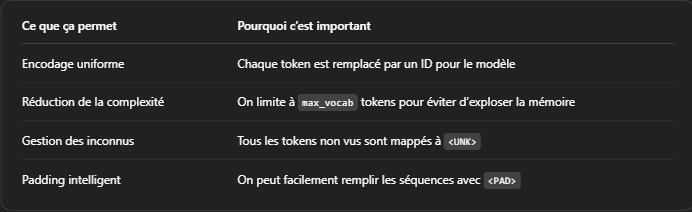

✅ Résumé

La fonction build_vocab :

Analyse tous les codes source.

Garde les tokens les plus fréquents.

Attribue un index unique à chaque token.

Prépare les données à passer dans un réseau de neurones (embeddings → LSTM → etc).

# **7. Création du Dataset PyTorch**

In [ ]:
import torch
from torch.utils.data import Dataset

class CodeBugDataset(Dataset):
    def __init__(self, data, token_to_idx, max_len=256):
        self.samples = []
        for entry in data:
            tokens = tokenize_code(entry["func"])
            ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:max_len]]
            ids += [token_to_idx["<PAD>"]] * (max_len - len(ids))  # padding
            label = entry["target"]
            self.samples.append((ids, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x), torch.tensor(y, dtype=torch.float)


**🔍 À quoi sert cette classe ?**

Elle crée un objet Dataset personnalisé pour PyTorch qui permet :

de lire un exemple à la fois,

de transformer le code source en vecteurs de tokens numériques,

d'ajouter du padding pour que toutes les séquences aient la même taille,

de retourner les données prêtes à être utilisées par un modèle PyTorch.

🧠 Pourquoi c’est super utile ?


 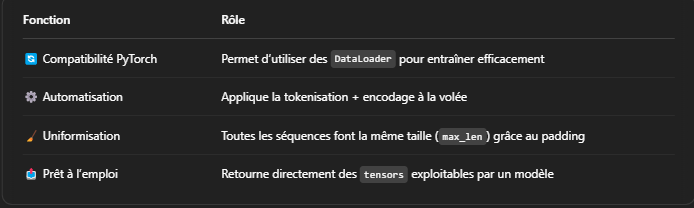

**📌 Résumé**

La classe CodeBugDataset :

transforme chaque bout de code source en vecteurs numériques de taille fixe,

encode les labels,

et prépare les données pour l’entraînement dans un réseau de neurones PyTorch.

# **8. DataLoaders**

In [ ]:
from torch.utils.data import DataLoader

train_ds = CodeBugDataset(train_data, token_to_idx)
valid_ds = CodeBugDataset(valid_data, token_to_idx)
test_ds = CodeBugDataset(test_data, token_to_idx)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)


# **9. Définition du modèle**

In [ ]:
import torch.nn as nn

class BugClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)  #Transforme chaque token ID en vecteur : embedding
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)  # doubled hidden_dim for bidirectional  , 1 neurone de sortie → pour la classification binaire (bug ou pas).
        self.sigmoid = nn.Sigmoid()  #Applique la fonction sigmoïde pour obtenir une probabilité entre 0 et 1.

    def forward(self, x):
        x = self.embedding(x)
        _, (h, _) = self.lstm(x)
        out = self.fc(torch.cat([h[-2], h[-1]], dim=-1))  # Concatenate both directions : avant et arriere
        return self.sigmoid(out).squeeze()


**🧠 Pourquoi ce modèle est bien adapté ?**

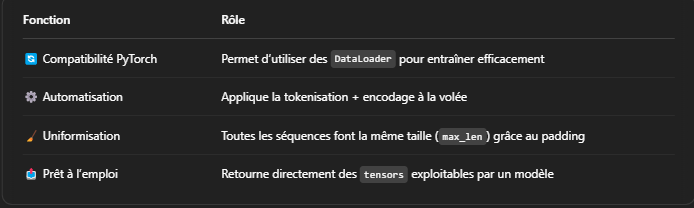

**✅ Résumé**

Le modèle BugClassifier :

Prend des séquences de tokens encodés

Les passe dans une couche d'embedding

Puis dans un LSTM bidirectionnel

Et enfin dans une couche linéaire + sigmoïde

Pour prédire si le code contient un bug ou non

C’est un modèle de classification binaire optimisé pour du code source séquentiel.

**🔁 Pourquoi un LSTM bidirectionnel ?**

Un LSTM standard lit la séquence dans un seul sens (de gauche à droite).

Mais dans beaucoup de cas, la **compréhension d’un mot/token dépend de ce qui vient avant et après.

Exemple en code C :

c
Copier
Modifier
if (a == b) {
    do_something();
}
Pour bien comprendre le rôle de ==, c’est utile de savoir ce qui vient avant ("a") et après ("b").

Un LSTM standard n’a que le passé (tokens précédents), mais pas le futur.

Un LSTM bidirectionnel lit de gauche à droite ET de droite à gauche, donc il comprend tout le contexte autour de chaque token.

**📌 Résumé**


Un LSTM bidirectionnel :

📖 Lit le code dans les deux sens

🧠 Permet de mieux comprendre les dépendances entre tokens

🚨 Améliore la détection de bugs contextuels

⚡ Est particulièrement efficace pour des séquences structurées comme le code

inconvenient : double calcul

# **10. Entraînement & Évaluation**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BugClassifier(len(vocab)).to(device)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_epoch(loader):
    model.train()
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            pred = model(x).cpu()
            preds += (pred > 0.5).int().tolist()
            targets += y.tolist()
    return accuracy_score(targets, preds)


# **11. Boucle d'entraînement**

In [ ]:
from sklearn.metrics import accuracy_score

# Train for 10 epochs
for epoch in range(20):
    loss = train_epoch(train_loader)
    acc = evaluate(valid_loader)
    print(f"Epoch {epoch+1} | Loss: {loss:.4f} | Val Accuracy: {acc:.4f}")

# Evaluate on the test set
test_acc = evaluate(test_loader)
print(f"Test Accuracy: {test_acc:.4f}")


Epoch 1 | Loss: 0.6842 | Val Accuracy: 0.5567
Epoch 2 | Loss: 0.6632 | Val Accuracy: 0.5776
Epoch 3 | Loss: 0.6419 | Val Accuracy: 0.6014
Epoch 4 | Loss: 0.6115 | Val Accuracy: 0.6007
Epoch 5 | Loss: 0.5736 | Val Accuracy: 0.5933
Epoch 6 | Loss: 0.5242 | Val Accuracy: 0.6072
Epoch 7 | Loss: 0.4732 | Val Accuracy: 0.6029
Epoch 8 | Loss: 0.4278 | Val Accuracy: 0.5999
Epoch 9 | Loss: 0.3866 | Val Accuracy: 0.6025
Epoch 10 | Loss: 0.3558 | Val Accuracy: 0.5886
Epoch 11 | Loss: 0.3202 | Val Accuracy: 0.6007
Epoch 12 | Loss: 0.2976 | Val Accuracy: 0.6065
Epoch 13 | Loss: 0.2703 | Val Accuracy: 0.5849
Epoch 14 | Loss: 0.2504 | Val Accuracy: 0.6018
Epoch 15 | Loss: 0.2326 | Val Accuracy: 0.5908
Epoch 16 | Loss: 0.2139 | Val Accuracy: 0.5966
Epoch 17 | Loss: 0.1965 | Val Accuracy: 0.5999
Epoch 18 | Loss: 0.1830 | Val Accuracy: 0.5915
Epoch 19 | Loss: 0.1734 | Val Accuracy: 0.5747
Epoch 20 | Loss: 0.2343 | Val Accuracy: 0.5988
Test Accuracy: 0.5681


In [ ]:
# Save model state_dict
torch.save(model.state_dict(), "bug_classifier.pth")

# Save vocabulary
import json
with open('vocab.json', 'w') as f:
    json.dump(vocab, f)


# **12.Testing buggy functions**

**Débordement de buffer**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    char buffer[10];
    strcpy(buffer, "This is a very long string!");  // Bug: Buffer overflow
    return 0;
}
"""))


Clean


**Division par zéro**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("int main() { int a = 5; int b = 0; int result = a / b; return 0; }"))


Clean


**Pointeur NULL**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int *ptr = NULL;
    *ptr = 10;  // Bug: Dereferencing a null pointer
    printf("%d", *ptr);
    return 0;
}

"""))


Clean


**Variable non initialisée**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int a;
    printf("%d", a);  // Bug: Using an uninitialized variable
    return 0;
}


"""))


Buggy


**Boucle infinie**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    while(1) {
        printf("This is an infinite loop\n");  // Bug: Infinite loop
    }
    return 0;
}


"""))


Buggy


# **13.Testing clean functions**

In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    printf("Hello, world!\n");
    return 0;
}

"""))


Buggy


In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int a = 5, b = 10;
    int sum = a + b;
    printf("Sum: %d\n", sum);
    return 0;
}

"""))


Clean


In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int n = 5, fact = 1;
    for(int i = 1; i <= n; i++) {
        fact *= i;
    }
    printf("Factorial: %d\n", fact);
    return 0;
}


"""))


Buggy


In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int num = 7;
    if (num % 2 == 0)
        printf("Even\n");
    else
        printf("Odd\n");
    return 0;
}



"""))


Buggy


In [ ]:
def predict_code(code):
    tokens = tokenize_code(code)
    ids = [token_to_idx.get(tok, token_to_idx["<UNK>"]) for tok in tokens[:256]]
    ids += [token_to_idx["<PAD>"]] * (256 - len(ids))
    input_tensor = torch.tensor([ids]).to(device)
    pred = model(input_tensor).item()
    return "Buggy" if pred > 0.5 else "Clean"

# Test the prediction function
print(predict_code("""
#include <stdio.h>

int main() {
    int arr[] = {1, 2, 3, 4, 5};
    for (int i = 0; i < 5; i++) {
        printf("%d ", arr[i]);
    }
    printf("\n");
    return 0;
}

"""))


Clean


# Testing and benshmarking





1. Training Time:

In [ ]:
import time

# Measure training time per epoch
start_time = time.time()
for epoch in range(20):
    loss = train_epoch(train_loader)
    acc = evaluate(valid_loader)
    print(f"Epoch {epoch+1} | Loss: {loss:.4f} | Val Accuracy: {acc:.4f}")
epoch_time = time.time() - start_time
print(f"Total training time: {epoch_time:.2f} seconds")


Epoch 1 | Loss: 0.1730 | Val Accuracy: 0.5842
Epoch 2 | Loss: 0.1507 | Val Accuracy: 0.6018
Epoch 3 | Loss: 0.1416 | Val Accuracy: 0.5952
Epoch 4 | Loss: 0.1295 | Val Accuracy: 0.5985
Epoch 5 | Loss: 0.1326 | Val Accuracy: 0.5930
Epoch 6 | Loss: 0.1199 | Val Accuracy: 0.5897
Epoch 7 | Loss: 0.1213 | Val Accuracy: 0.5860
Epoch 8 | Loss: 0.1068 | Val Accuracy: 0.5813
Epoch 9 | Loss: 0.1014 | Val Accuracy: 0.5857
Epoch 10 | Loss: 0.0984 | Val Accuracy: 0.5944
Epoch 11 | Loss: 0.1022 | Val Accuracy: 0.5849
Epoch 12 | Loss: 0.1001 | Val Accuracy: 0.5900
Epoch 13 | Loss: 0.0976 | Val Accuracy: 0.5937
Epoch 14 | Loss: 0.0951 | Val Accuracy: 0.5911
Epoch 15 | Loss: 0.0885 | Val Accuracy: 0.5860
Epoch 16 | Loss: 0.0843 | Val Accuracy: 0.5857
Epoch 17 | Loss: 0.0827 | Val Accuracy: 0.5882
Epoch 18 | Loss: 0.0814 | Val Accuracy: 0.5824
Epoch 19 | Loss: 0.0878 | Val Accuracy: 0.5900
Epoch 20 | Loss: 0.0868 | Val Accuracy: 0.5871
Total training time: 110.36 seconds


2. Classification Metrics:

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

# Function to evaluate all classification metrics
def evaluate_metrics(loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            pred = model(x).cpu()
            preds += (pred > 0.5).int().tolist()  # Threshold at 0.5 for binary classification
            targets += y.tolist()

    precision = precision_score(targets, preds)
    recall = recall_score(targets, preds)
    f1 = f1_score(targets, preds)
    cm = confusion_matrix(targets, preds)
    auc_roc = roc_auc_score(targets, preds)

    return precision, recall, f1, cm, auc_roc

# Evaluate classification metrics on validation set
precision, recall, f1, cm, auc_roc = evaluate_metrics(valid_loader)
print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1 Score: {f1:.4f} | AUC-ROC: {auc_roc:.4f}")


Precision: 0.5229 | Recall: 0.5670 | F1 Score: 0.5441 | AUC-ROC: 0.5848


3. Confusion Matrix:

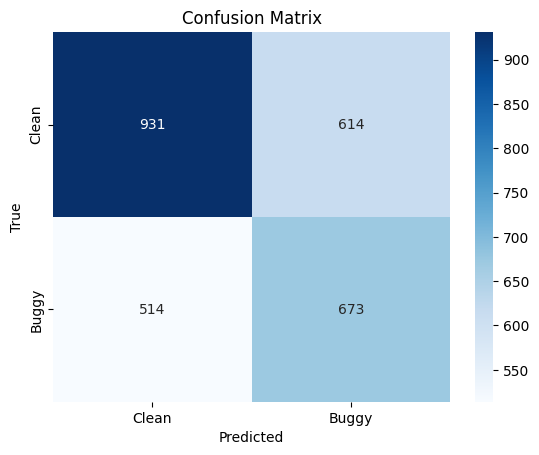

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot confusion matrix
def plot_confusion_matrix(cm):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Clean", "Buggy"], yticklabels=["Clean", "Buggy"])
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

plot_confusion_matrix(cm)


4. Inference Time:

In [ ]:
# Measure inference time for a single prediction
start_time = time.time()
prediction = predict_code("""int main() {return 0;}""")
inference_time = time.time() - start_time
print(f"Inference time for single sample: {inference_time:.4f} seconds")


Inference time for single sample: 0.0076 seconds


5. Model Size:

In [ ]:
import os

# Save the model to measure size
torch.save(model.state_dict(), "bug_classifier.pth")

# Measure model size (in MB)
model_size = os.path.getsize("bug_classifier.pth") / (1024 * 1024)  # in MB
print(f"Model size: {model_size:.2f} MB")


Model size: 3.20 MB


Next Steps to Improve:

Hyperparameter Tuning:

**Hyperparameter Tuning: Learning Rate and Batch Size Example**

Here’s how you can start with learning rate and batch size tuning using a grid search approach. This example will loop through multiple combinations of learning rates and batch sizes:

In [ ]:
import torch.optim as optim

# Define a function to train and evaluate the model for specific hyperparameters
def train_and_evaluate(learning_rate, batch_size):
    # Update the batch size
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_ds, batch_size=batch_size)

    # Initialize the model, loss function, and optimizer
    model = BugClassifier(len(vocab)).to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss()

    # Train for 5 epochs (or you can adjust based on available time)
    for epoch in range(5):
        loss = train_epoch(train_loader)
        acc = evaluate(valid_loader)
        print(f"Epoch {epoch+1} | Loss: {loss:.4f} | Val Accuracy: {acc:.4f}")

    # Evaluate on validation set
    val_acc = evaluate(valid_loader)
    return val_acc

# List of hyperparameters to tune
learning_rates = [1e-3, 1e-4, 1e-5]
batch_sizes = [32, 64, 128]

# Try all combinations of learning rate and batch size
best_acc = 0
best_lr = None
best_batch_size = None

for lr in learning_rates:
    for batch_size in batch_sizes:
        print(f"\nTraining with Learning Rate = {lr} and Batch Size = {batch_size}")
        acc = train_and_evaluate(lr, batch_size)
        print(f"Validation Accuracy: {acc:.4f}")

        # Keep track of the best performance
        if acc > best_acc:
            best_acc = acc
            best_lr = lr
            best_batch_size = batch_size

print(f"\nBest Validation Accuracy: {best_acc:.4f} with Learning Rate = {best_lr} and Batch Size = {best_batch_size}")



Training with Learning Rate = 0.001 and Batch Size = 32
Epoch 1 | Loss: 0.1510 | Val Accuracy: 0.5974
Epoch 2 | Loss: 0.1164 | Val Accuracy: 0.5966
Epoch 3 | Loss: 0.1014 | Val Accuracy: 0.5911
Epoch 4 | Loss: 0.0992 | Val Accuracy: 0.5897
Epoch 5 | Loss: 0.1058 | Val Accuracy: 0.5944
Validation Accuracy: 0.5944

Training with Learning Rate = 0.001 and Batch Size = 64
Epoch 1 | Loss: 0.0772 | Val Accuracy: 0.5893
Epoch 2 | Loss: 0.0628 | Val Accuracy: 0.5882
Epoch 3 | Loss: 0.0592 | Val Accuracy: 0.5926
Epoch 4 | Loss: 0.0575 | Val Accuracy: 0.5893
Epoch 5 | Loss: 0.0567 | Val Accuracy: 0.5941
Validation Accuracy: 0.5941

Training with Learning Rate = 0.001 and Batch Size = 128
Epoch 1 | Loss: 0.0493 | Val Accuracy: 0.5871
Epoch 2 | Loss: 0.0455 | Val Accuracy: 0.5802
Epoch 3 | Loss: 0.0441 | Val Accuracy: 0.5871
Epoch 4 | Loss: 0.0482 | Val Accuracy: 0.5853
Epoch 5 | Loss: 0.0442 | Val Accuracy: 0.5813
Validation Accuracy: 0.5813

Training with Learning Rate = 0.0001 and Batch Size =

**Explanation:**

This function runs the training and evaluation with different combinations of learning rate and batch size.

We loop through the hyperparameters and track the best validation accuracy to find the optimal combination.

Now that we've identified a promising combination, you can continue training the model for more epochs (e.g., 10-20 epochs) to allow it to further improve its performance.

**Continue Training for More Epochs (with Early Stopping)**

We’ll extend the training process, implement early stopping, and monitor performance on both the training and validation sets to avoid overfitting. This approach will help you train for more epochs, but stop early if the model stops improving.

In [ ]:
import torch
import numpy as np

# Early stopping parameters
patience = 5  # Number of epochs with no improvement before stopping
best_val_acc = 0
epochs_without_improvement = 0

# Training for more epochs with early stopping
num_epochs = 20
for epoch in range(num_epochs):
    loss = train_epoch(train_loader)
    val_acc = evaluate(valid_loader)

    print(f"Epoch {epoch+1} | Loss: {loss:.4f} | Val Accuracy: {val_acc:.4f}")

    # Check for improvement in validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0
        # Save the best model
        torch.save(model.state_dict(), "best_bug_classifier.pth")
    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch+1} with validation accuracy {val_acc:.4f}")
        break


Epoch 1 | Loss: 0.0754 | Val Accuracy: 0.5908
Epoch 2 | Loss: 0.0791 | Val Accuracy: 0.5853
Epoch 3 | Loss: 0.0641 | Val Accuracy: 0.5849
Epoch 4 | Loss: 0.0586 | Val Accuracy: 0.5776
Epoch 5 | Loss: 0.0614 | Val Accuracy: 0.5791
Epoch 6 | Loss: 0.0574 | Val Accuracy: 0.5838
Early stopping at epoch 6 with validation accuracy 0.5838



Test Accuracy: 0.5494
Test Precision: 0.5087
Test Recall: 0.5586
Test F1 Score: 0.5325
Test AUC-ROC: 0.5501


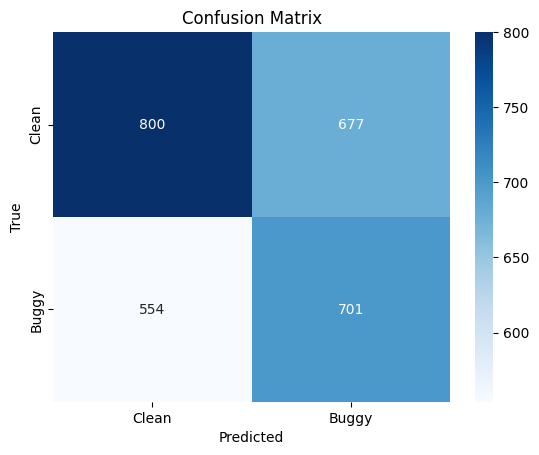

In [ ]:
# Evaluate the model on the test set
test_acc = evaluate(test_loader)
test_precision, test_recall, test_f1, test_cm, test_auc_roc = evaluate_metrics(test_loader)

print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")
print(f"Test AUC-ROC: {test_auc_roc:.4f}")

# Plot confusion matrix
plot_confusion_matrix(test_cm)


**data augmentation**


✅ Step 1: Check Class Distribution

In [ ]:
from collections import Counter

# Assuming "target" is the name of the label column
labels = [entry["target"] for entry in train_data]
label_counts = Counter(labels)
print("Class distribution in training set:", label_counts)

Class distribution in training set: Counter({False: 11836, True: 10018})


➕ Cell 2: Oversample the Minority Class

In [ ]:
import random

# Separate buggy and clean samples
buggy_samples = [sample for sample in train_data if sample['target'] == 1] # Access using 'target' column
clean_samples = [sample for sample in train_data if sample['target'] == 0] # Access using 'target' column

# Oversample the minority class
if len(buggy_samples) > len(clean_samples):
    clean_oversampled = random.choices(clean_samples, k=len(buggy_samples))
    balanced_train_data = buggy_samples + clean_oversampled
else:
    buggy_oversampled = random.choices(buggy_samples, k=len(clean_samples))
    balanced_train_data = clean_samples + buggy_oversampled

# Shuffle the final balanced dataset
random.shuffle(balanced_train_data)

🔄 Cell 3: Create DataLoader with Balanced Data

In [ ]:
# Load balanced dataset into DataLoader
balanced_train_ds = CodeBugDataset(balanced_train_data, token_to_idx)
balanced_train_loader = DataLoader(balanced_train_ds, batch_size=64, shuffle=True)


🧠 Cell 4: Reinitialize Model and Optimizer

In [ ]:
# Reinitialize model and optimizer for training from scratch
model = BugClassifier(len(vocab)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


🔁 Cell 5: Train on Balanced Data

In [ ]:
# Training loop on balanced dataset
for epoch in range(10):
    loss = train_epoch(balanced_train_loader)
    acc = evaluate(valid_loader)
    print(f"Epoch {epoch+1} | Loss: {loss:.4f} | Val Accuracy: {acc:.4f}")


Epoch 1 | Loss: 0.6844 | Val Accuracy: 0.5322
Epoch 2 | Loss: 0.6573 | Val Accuracy: 0.5875
Epoch 3 | Loss: 0.6132 | Val Accuracy: 0.5981
Epoch 4 | Loss: 0.5515 | Val Accuracy: 0.5926
Epoch 5 | Loss: 0.4811 | Val Accuracy: 0.6138
Epoch 6 | Loss: 0.4080 | Val Accuracy: 0.6047
Epoch 7 | Loss: 0.3503 | Val Accuracy: 0.6054
Epoch 8 | Loss: 0.2997 | Val Accuracy: 0.5922
Epoch 9 | Loss: 0.2619 | Val Accuracy: 0.6021
Epoch 10 | Loss: 0.2255 | Val Accuracy: 0.5966


✅ 📊 Cell 6: Final Metrics with Detailed Output


📌 Classification Report:

              precision    recall  f1-score   support

         0.0     0.5900    0.6500    0.6186      1477
         1.0     0.5321    0.4685    0.4983      1255

    accuracy                         0.5666      2732
   macro avg     0.5611    0.5592    0.5584      2732
weighted avg     0.5634    0.5666    0.5633      2732


📈 AUC-ROC: 0.5848


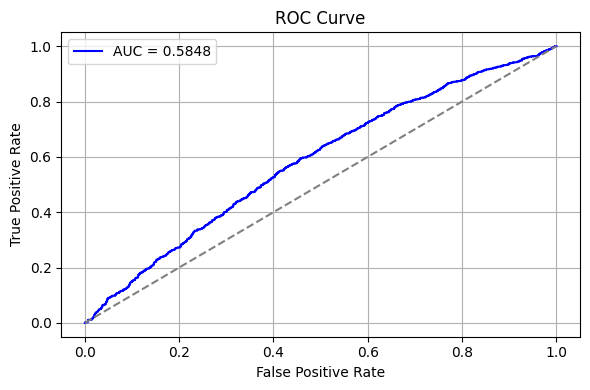

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

def evaluate_metrics(loader):
    model.eval()
    all_preds, all_probs, all_targets = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            probs = model(x).cpu()
            preds = (probs > 0.5).int()
            all_preds.extend(preds.numpy())
            all_probs.extend(probs.numpy())
            all_targets.extend(y.numpy())

    # Classification report
    print("\n📌 Classification Report:\n")
    print(classification_report(all_targets, all_preds, digits=4))

    # AUC-ROC score
    auc = roc_auc_score(all_targets, all_probs)
    print(f"\n📈 AUC-ROC: {auc:.4f}")

    # ROC curve
    fpr, tpr, _ = roc_curve(all_targets, all_probs)
    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}", color='blue')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Lancer l'évaluation sur le test_loader
evaluate_metrics(test_loader)


**✅ Ce que montre la courbe ROC :**

Elle trace :

Axe X = Taux de faux positifs (FPR) :
→ C’est le pourcentage de cas non buggy que ton modèle a faussement prédits comme buggy.

Axe Y = Taux de vrais positifs (TPR) ou Recall :
→ C’est le pourcentage de bugs réels que ton modèle a correctement détectés.

📊 AUC (Area Under Curve) :
AUC = 1.0 : parfait

AUC = 0.5 : aléatoire

AUC < 0.5 : mauvais, prédiction inversée

Ton AUC = ~0.58 : ton modèle capte un peu d'information utile, mais reste faible → à améliorer.



**Analyse rapide :**

Le modèle est meilleur pour reconnaître les fonctions propres (non buggées) que pour détecter les buggy.

Le recall faible pour la classe "buggy" indique qu’il manque beaucoup de bugs → c’est problématique dans ton cas.

L’ensemble des métriques tourne autour de 56% : un peu mieux qu’un classifieur aléatoire (50%), mais améliorable.



# emplacer LSTM par BiGRU

voir prochain notebook